
# OpenMP K-Means
**Dataset**: `datasets/100000x5.csv` (100k punten, 5 dim)  

In [12]:
import os
import sys
import csv
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

os.environ["MPLCONFIGDIR"] = "/tmp"

# Detect project root directory whether running from docs/ or project root
current_dir = os.path.abspath(os.getcwd())
if os.path.basename(current_dir) == "docs":
    PROJECT_ROOT = os.path.dirname(current_dir)
else:
    PROJECT_ROOT = current_dir

RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
print(f"Project root: {PROJECT_ROOT}")
print(f"Results dir:  {RESULTS_DIR}")

# Matplotlib styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
    "figure.titlesize": 14,
    "grid.alpha": 0.3
})

def load_results(csv_name):
    path = os.path.join(RESULTS_DIR, csv_name)
    if not os.path.exists(path):
        raise FileNotFoundError(f"Resultatenbestand niet gevonden: {path}")
    rows = []
    with open(path, newline="") as fh:
        for r in csv.reader(fh):
            if not r or r[0].startswith("#") or r[0] in ("label", "Type"):
                continue
            if len(r) == 8:    # label,mode,threads,run,reps,bestdist,seconds,steps
                label, mode, threads, run, _, bestdist, seconds, steps = r
            elif len(r) == 7:  # label,mode,threads,run,bestdist,seconds,steps
                label, mode, threads, run, bestdist, seconds, steps = r
            elif len(r) == 6:  # label,threads,run,bestdist,seconds,steps (mode omitted)
                label, threads, run, bestdist, seconds, steps = r
                mode = label
            elif len(r) == 10: # raw kmeans stdout with submode
                label, mode, _, threads, _, _, _, _, bestdist, seconds = r
                run, steps = 1, ""
            elif len(r) == 9:  # raw kmeans stdout without submode
                label, _, threads, _, _, _, _, bestdist, seconds = r
                mode, run, steps = label, 1, ""
            else:
                continue
            rows.append({
                "label": label,
                "mode": mode or label,
                "threads": int(threads),
                "run": int(run),
                "bestdist": float(bestdist),
                "seconds": float(seconds),
                "steps": steps,
            })
    return pd.DataFrame(rows)

Project root: /home/matha/Projects/c/uni/pds/kmeans
Results dir:  /home/matha/Projects/c/uni/pds/kmeans/results


## 2. Seriële Baseline vs OpenMP op 1 Thread

=== Executietijden op 1 Thread (Overhead Analyse) ===
        mode  seconds  overhead_vs_serial_%
         omp 8.068637             78.810447
   omp-naive 3.572683            -20.825149
      serial 4.512397              0.000000
serial-naive 4.524107              0.259507


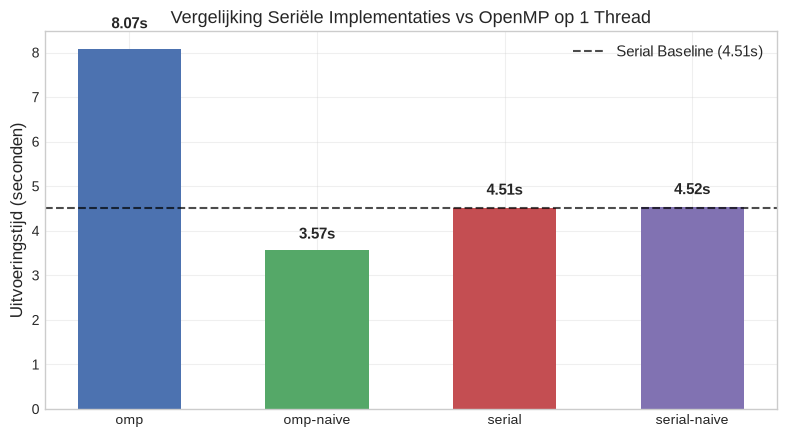

In [13]:
df_svo = load_results("serial_vs_omp.csv")

svo_summary = df_svo.groupby(["mode", "threads"], as_index=False)["seconds"].mean()

t1_data = svo_summary[svo_summary["threads"] == 1].copy()
serial_rows = t1_data[t1_data["mode"] == "serial"]["seconds"]
t_serial_base = serial_rows.iloc[0] if not serial_rows.empty else t1_data["seconds"].iloc[0]
t1_data["overhead_vs_serial_%"] = ((t1_data["seconds"] - t_serial_base) / t_serial_base) * 100

print("=== Executietijden op 1 Thread (Overhead Analyse) ===")
print(t1_data[["mode", "seconds", "overhead_vs_serial_%"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(t1_data["mode"], t1_data["seconds"], color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"], width=0.55)
ax.axhline(t_serial_base, color="black", linestyle="--", alpha=0.7, label=f"Serial Baseline ({t_serial_base:.2f}s)")

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.05 * yval, f"{yval:.2f}s", ha="center", va="bottom", fontweight="bold")

ax.set_ylabel("Uitvoeringstijd (seconden)")
ax.set_title("Vergelijking Seriële Implementaties vs OpenMP op 1 Thread")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Thread Scaling, Speedup en Efficiëntie

In [ ]:
df_scaling = load_results("thread_scaling.csv")

# gemiddelde, steekproef-standaardafwijking (ddof=1) en aantal herhalingen per (mode, threads)
scaling_summary = (
    df_scaling.groupby(["mode", "threads"])["seconds"]
    .agg(seconds="mean", std="std", n_runs="count")
    .reset_index()
)

scaling_results = []
for mode, group in scaling_summary.groupby("mode"):
    t1_rows = group[group["threads"] == 1]
    ref = t1_rows.iloc[0] if not t1_rows.empty else group.sort_values("threads").iloc[0]
    t1, s1 = ref["seconds"], ref["std"]
    g = group.copy()
    g["t1"] = t1
    g["speedup"] = t1 / g["seconds"]
    # foutpropagatie voor een quotient S = T1 / Tp (onafhankelijke metingen)
    g["speedup_std"] = g["speedup"] * np.sqrt((s1 / t1) ** 2 + (g["std"] / g["seconds"]) ** 2)
    g.loc[g["threads"] == 1, "speedup_std"] = 0.0  # referentie: S = 1 per definitie
    g["efficiency_%"] = (g["speedup"] / g["threads"]) * 100
    g["efficiency_std_%"] = (g["speedup_std"] / g["threads"]) * 100
    scaling_results.append(g)

df_analysis = pd.concat(scaling_results, ignore_index=True)
print(f"=== Thread Scaling, Speedup en Efficiëntie (gemiddelde ± std over {int(df_analysis['n_runs'].min())} runs) ===")
print(df_analysis[["mode", "threads", "seconds", "std", "speedup", "speedup_std", "efficiency_%", "efficiency_std_%"]].to_string(index=False))

# plot speedup en efficiëntie, met foutbalken (±1 std)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

threads_range = np.sort(df_analysis["threads"].unique())

# Subplot 1: Speedup
for mode, group in df_analysis.groupby("mode"):
    ax1.errorbar(group["threads"], group["speedup"], yerr=group["speedup_std"],
                 marker="o", linewidth=2, capsize=3, label=f"{mode}")
ax1.plot(threads_range, threads_range, "k--", alpha=0.5, label="Ideaal (S = p)")
ax1.set_xlabel("Aantal Threads (p)")
ax1.set_ylabel("Speedup (S_p)")
ax1.set_title("Speedup vs Aantal Threads (±1 std)")
ax1.set_xticks(threads_range)
ax1.legend()

# Subplot 2: Parallelle Efficiëntie
for mode, group in df_analysis.groupby("mode"):
    ax2.errorbar(group["threads"], group["efficiency_%"], yerr=group["efficiency_std_%"],
                 marker="s", linewidth=2, capsize=3, label=f"{mode}")
ax2.axhline(100, color="k", linestyle="--", alpha=0.5, label="Ideaal (100%)")
ax2.set_xlabel("Aantal Threads (p)")
ax2.set_ylabel("Efficiëntie (%)")
ax2.set_title("Parallelle Efficiëntie vs Aantal Threads (±1 std)")
ax2.set_xticks(threads_range)
ax2.set_ylim(0, 120)
ax2.legend()

plt.tight_layout()
plt.show()

## 4. Seriele fractie && wet van Ahmdal 

In [15]:
# Amdahl-analyse (Vraag 4, 5 en 6)
omp_group = df_analysis[df_analysis["mode"] == "omp"].sort_values("threads")
if omp_group.empty:
    omp_group = df_analysis.sort_values("threads")

t1 = omp_group[omp_group["threads"] == 1]["seconds"].iloc[0]

# Vraag 4: Schat seriële en parallelle fractie op basis van 8 threads
row_8 = omp_group[omp_group["threads"] == 8].iloc[0] if not omp_group[omp_group["threads"] == 8].empty else omp_group.iloc[-1]
p8 = row_8["threads"]
s8 = row_8["speedup"]
P_8 = (1.0 - 1.0 / s8) / (1.0 - 1.0 / p8)
serial_frac_8 = 1.0 - P_8

print(f"=== Vraag 4: Schatting uit p = {int(p8)} threads ===")
print(f"Gemeten T(1) = {t1:.4f}s, T({int(p8)}) = {row_8['seconds']:.4f}s -> Speedup S({int(p8)}) = {s8:.2f}")
print(f"Parallelle fractie P = {P_8 * 100:.2f}% | Seriële fractie (1 - P) = {serial_frac_8 * 100:.2f}%\n")

# Vraag 5: Voorspel T(16) en S(16) op basis van P_8 en vergelijk met meting op 16 threads
pred_s16 = 1.0 / (serial_frac_8 + P_8 / 16.0)
pred_t16 = t1 * (serial_frac_8 + P_8 / 16.0)
print("=== Vraag 5: Voorspelling vs Meting voor p = 16 threads ===")
print(f"Voorspelde T(16) = {pred_t16:.4f}s (voorspelde speedup S(16) = {pred_s16:.2f})")
if not omp_group[omp_group["threads"] == 16].empty:
    row_16 = omp_group[omp_group["threads"] == 16].iloc[0]
    meas_t16, meas_s16 = row_16["seconds"], row_16["speedup"]
    diff_pct = ((meas_t16 - pred_t16) / pred_t16) * 100
    P_16 = (1.0 - 1.0 / meas_s16) / (1.0 - 1.0 / 16.0)
    print(f"Gemeten    T(16) = {meas_t16:.4f}s (gemeten speedup    S(16) = {meas_s16:.2f}, afwijking: {diff_pct:+.1f}%)")
    print(f"Terugberekende P uit 16 threads: P = {P_16 * 100:.2f}% (seriële fractie = {(1.0 - P_16) * 100:.2f}%)\n")

# Vraag 6: Limiet voor oneindig veel cores (p -> inf)
t_inf_8 = serial_frac_8 * t1
s_inf_8 = 1.0 / serial_frac_8
print("=== Vraag 6: Limiet voor oneindig aantal cores (p -> inf) ===")
print(f"Op basis van p=8  (P={P_8*100:.2f}%): T(inf) = {t_inf_8:.4f}s | Max theoretische speedup S(inf) = {s_inf_8:.2f}")
if not omp_group[omp_group["threads"] == 16].empty:
    t_inf_16 = (1.0 - P_16) * t1
    s_inf_16 = 1.0 / (1.0 - P_16)
    print(f"Op basis van p=16 (P={P_16*100:.2f}%): T(inf) = {t_inf_16:.4f}s | Max theoretische speedup S(inf) = {s_inf_16:.2f}")


Geschatte parallelle fractie (P): 93.52%
Geschatte max speedup (P): 15.43


# 5. Inner Loop Evolutie: omp-naive vs Geoptimaliseerd omp met changing K

=== Vergelijking omp-naive vs omp voor Verschillende K (12 Threads) ===
 k      mode    seconds
 2       omp   0.383688
 2 omp-naive  10.527290
10       omp   1.332850
10 omp-naive  41.596000
50       omp   9.294543
50 omp-naive 106.151800


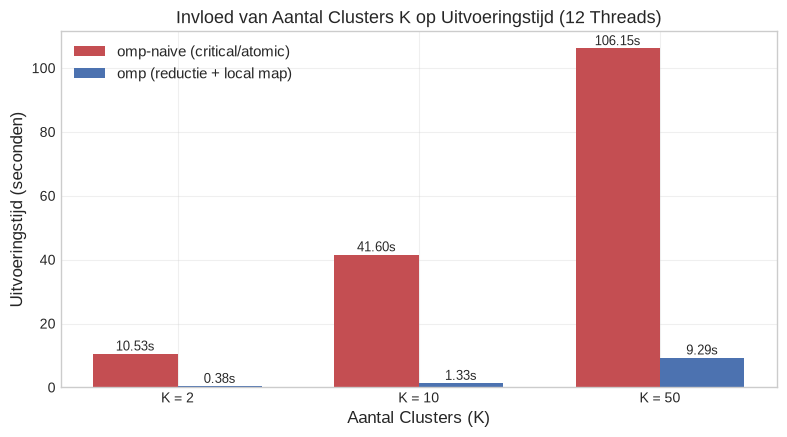

In [18]:
df_inner = load_results("inner_first_vs_latest.csv")

df_k = df_inner[df_inner["label"].str.startswith("inner_k")].copy()
df_k["k"] = df_k["label"].str.extract(r"inner_k(\d+)").astype(int)

k_threads = int(df_k["threads"].iloc[0]) if not df_k.empty else 8
k_summary = df_k.groupby(["k", "mode"], as_index=False)["seconds"].mean()
print(f"=== Vergelijking omp-naive vs omp voor Verschillende K ({k_threads} Threads) ===")
print(k_summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
k_vals = sorted(k_summary["k"].unique())
x = np.arange(len(k_vals))
width = 0.35

naive_times = [k_summary[(k_summary["k"] == k) & (k_summary["mode"] == "omp-naive")]["seconds"].values[0] for k in k_vals]
omp_times = [k_summary[(k_summary["k"] == k) & (k_summary["mode"] == "omp")]["seconds"].values[0] for k in k_vals]

rects1 = ax.bar(x - width/2, naive_times, width, label="omp-naive (critical/atomic)", color="#C44E52")
rects2 = ax.bar(x + width/2, omp_times, width, label="omp (reductie + local map)", color="#4C72B0")

for bar in rects1 + rects2:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, y + 0.2, f"{y:.2f}s", ha="center", va="bottom", fontsize=9)

ax.set_xlabel("Aantal Clusters (K)")
ax.set_ylabel("Uitvoeringstijd (seconden)")
ax.set_title(f"Invloed van Aantal Clusters K op Uitvoeringstijd ({k_threads} Threads)")
ax.set_xticks(x)
ax.set_xticklabels([f"K = {k}" for k in k_vals])
ax.legend()
plt.tight_layout()
plt.show()

### Observaties & Verklaring:
- **`omp-naive`**: Bij kleine K is de rekentijd per punt klein, waardoor de relatieve overhead van het wachten op `#pragma omp critical` dominant is.
- **`omp`**: Blijft beter schalen over threads dankzij de reducties op scalairen en het lock-vrij accumuleren in thread-private `localCentroidMap` structuren.